# MA22037 coursework (2025-26). Felix Galka (fg551)


# TODOs / Notes (Delete)
- Juypter -> Save as HMTL -> CTRL+P -> Save as PDF -> mess with margins
- GenAI statement
- add dx to integrals
- look on iPad to see if looks good
- add useful comments to code
- make graphs nice
- consider small fractions and make them bigger
- prove B3 end (analytic etc)
- prove A5 part 3

# Gen-AI Statement

I used Generative AI for the following things within this notebook:
- Finding previously unused LaTeX symbols such as $ \left[...\right]_0^1 $ and piecewise function definition in LaTeX (A2)
- Explaining Parseval's Theorem, the proof, and how to use it within A5. As a joint honours student, I couldn't take Analysis 1A/1B/2 which covers Parseval's theorem and the tools to prove it.

# Section A

## A1

**a)**
<br><br> Using the Fourier expression of $ u(x) $,


$$
\int_0^1 |u(x)|^2 \ dx = \int_0^1 \left | \sum_{k=-\infty}^{\infty} u_k e^{2k \pi i x} \right | ^2
$$

By using 
$$
~\sum_{k=-\infty}^\infty | f(x) | ^2 = \sum_{k=-\infty}^\infty \sum_{j=-\infty}^\infty f_k(x)\overline{(f_j(x))} 
$$,

$$
\begin{align*}
\int_0^1 |u(x)|^2 \ dx &= \int_0^1 \sum_{k=-\infty}^\infty \sum_{j=-\infty}^\infty u_k \bar{u_j} e^{2 \pi i x (k-j)} \ dx \\
& = \sum_{k,j=-\infty}^\infty \int_0^1 u_k \bar{u_j} e^{2 \pi i x (k-j)} \ dx \\
& = \sum_{k,j=-\infty}^\infty u_k \bar{u_j} \int_0^1  e^{2 \pi i x (k-j)} \ dx \hspace{10mm} \mathbf{(1)}
\end{align*}
$$

Now, we prove that the integral in $ \mathbb{(1)} $ follows the Kronecker delta $ \delta_{j,k} $

$$
\begin{align*}
\int_0^1  e^{2 \pi i x (k-j)} \ dx & = \left[ \frac{e^{2\pi i (k-j)x}}{2\pi i (k-j)} \right]_{0}^{1} \\
& = \frac{1}{2\pi i (k-j)}\left[e^{2 \pi i (k-j)} - 1  \right]
\end{align*}
$$

Since $ (k-j) \in \mathbb{Z}, \ \ e^{2(k-j) \pi i} = 1 $ , and thus $ \mathbf{(1)} = 0 $ for $ k \neq j $.
<br> For $ k = j, \mathbb{(1)} $ becomes $ \int_0^1e^0 \ dx = \int_0^11 \ dx = 1 \hspace{3mm} \square$
<br>
<br> Back to the original proof now, the double sum simplifies as follows:

$$
\begin{align*}
\int_0^1 |u(x)|^2 \ dx & = \sum_{k,j = - \infty}^{\infty} u_k \bar{u_j} \delta_{k,j} \\
& = \sum_{k = - \infty}^{\infty} u_k \bar{u_k} \\
& = \sum_{k = - \infty}^{\infty} | u_k |^2 \hspace{3mm} \square
\end{align*}
$$

<br><br> **b)**

Using Hint 2, 

$$
\begin{align*}
u(x) \times e^{-2k \pi i x} & = \sum_{j=- \infty}^{\infty} u_j e^{2j \pi i x} \times e^{-2k \pi i x} \\
& = \sum_{j=- \infty}^{\infty} u_j e^{2(j-k) \pi i x}
\end{align*}
$$

Now, integrating over [0,1],

$$
\begin{align*}
\int_0^1 \sum_{j=- \infty}^{\infty} u_j e^{2(j-k) \pi i x} & = \sum_{j=- \infty}^{\infty} u_j \int_0^1 e^{2(j-k) \pi i x} \\
& = \sum_{j=- \infty}^{\infty} u_j \delta_{j,k} \hspace{5mm} \ from \ \mathbf{(1)} \\
& = u_k \hspace{3mm} \square
\end{align*}
$$



## A2

We can use the result from A1 part b) to directly compute the Fourier coefficients for u(x)

$$
\begin{align*}
u_k 
& = \int_0^1u(x) \times e^{-2 \pi k i x} \\
& = \int_0^{1/2} 0 \times e^{-2 \pi k i x} + \int_{1/2}^1 1 \times e^{-2 \pi k i x} \\
& = \int_{1/2}^1 e^{-2 \pi k i x} \\
& = \frac{\left[ e^{-2 \pi i k x} \right]_{1/2}^1}{-2 \pi i k} \\ \\
& = \frac{\left[ e^{-2 \pi i k} - e^{- \pi i k} \right]}{- 2 \pi i k} \\
\end{align*}
$$
However, $e^{-2 \pi k i} = 1$ and $ e^{- \pi k i} = (-1)^k $
<br> $u_k$ thus simplifies to:

$$
\begin{align*}
u_k 
& = \frac{1 -(-1)^k}{- 2 \pi i k} \\ \\
& = \frac{(-1)^k - 1}{2 \pi i k}
\end{align*}
$$

Considering the case k = 0, we observe

$$
\begin{align*}
u_0 = \int_0^1 u(x)e^0 = \frac{1}{2}
\end{align*}
$$

Finally,

$$
\
u_k =
\begin{cases}
\text{ $\frac{1}{2}$ }, & \text{k=0} \\
\text{0}, & \text{k \ even} \\
\text{$\frac{i}{\pi k}$}, & \text{k \ odd}
\end{cases}
\
$$






## A3

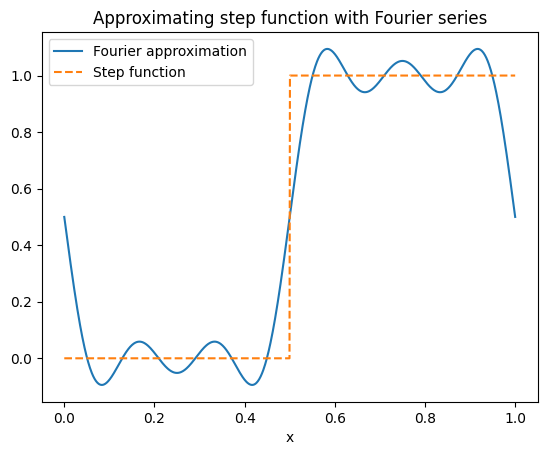

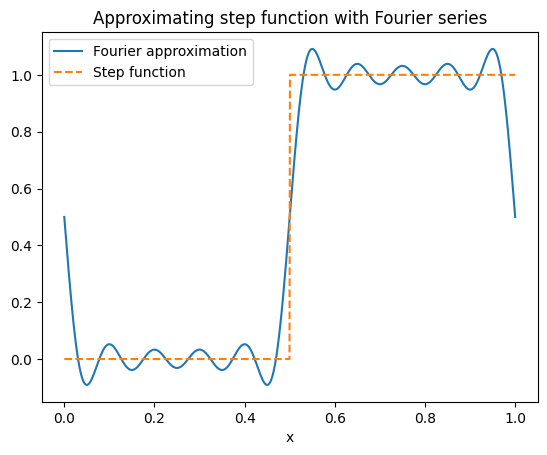

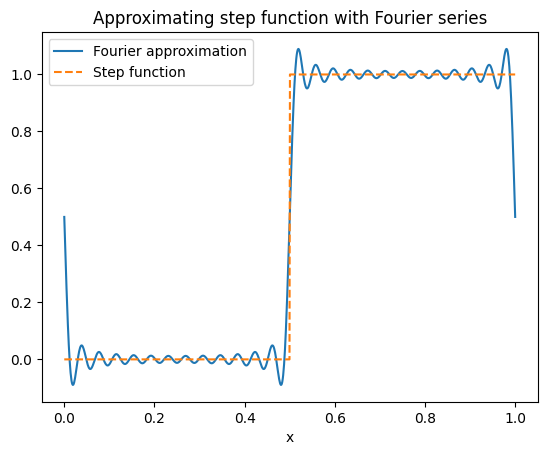

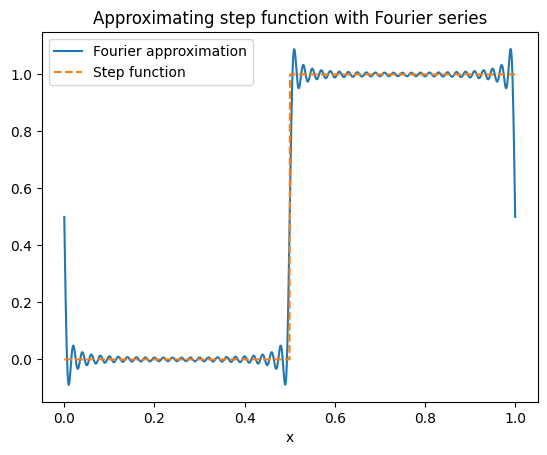

In [32]:
import numpy as np

def eval_uj(J, x):
	uJ_x = 0
	for k in range(-J, J + 1):
		u_k = 0
		if k == 0:
			u_k = 1/2
		elif k % 2 == 0:
			u_k = 0
		else:
			u_k = 1j / (np.pi * k)
		uJ_x += (u_k * np.exp(2 * np.pi * 1j * k * x))
	return uJ_x

def step_fn(J):
	N=1000
	grid=np.linspace(0,1,N)
	uJ = []
	for point in grid:
		uJ.append(eval_uj(J, point).real)
	return grid, uJ

import matplotlib.pyplot as plt

step = [0 if x < 1/2 else 1 for x in np.linspace(0,1,1000)]

J = [5,10,25,50]
for j in J:
	x, y = step_fn(j)
	plt.plot(x, y, label="Fourier approximation")
	plt.plot(x, step, linestyle="dashed", label="Step function")
	plt.xlabel("x"); plt.title("Approximating step function with Fourier series"); plt.legend()
	plt.show()
print()

### Main features of approximation
* The approximation gets more accurate the further away it is from discontinuous points / end points.
* The approximation is worst at the end points, with massive errors occuring as x $\rightarrow$ 1 and x $\leftarrow$ 0.
* Even comparing J=5 and J=50, the scale of the errors at x=0 and x=1 stay the same, they just happen closer to the endpoint.
* As J increases, the peaks and trophs of the sin/cos oscillations get smaller in magnitude, thus approximating the line better.

### Gibbs' Phenomenon
Gibbs' Phenomenon occurs when approximating discontinuous functions with oscillating functions, not unique to Fourier series but commonly found in such approximations. <br> At discontinuous points (x=0, x=1/2, x=1 for example), Gibbs' Phenomenon says that the approximation will overshoot by roughly 9%, with this jump being a lot more in our case.

References
<br>
* *https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/05cce833730ffd3c39f420a41ad82fd6_MIT18_03SCF11_s22_7text.pdf*

## A4

Repeating the above process for $u(x) = x^2 - x$,
$$
\begin{align*}
u_k 
& = \int_0^1u(x) \times e^{-2 \pi k i x} \ dx \\
& = \int_0^1 (x^2 - x) e^{-2 \pi k i x} \ dx \\
& = \int_0^1 x^2 e^{-2 \pi k i x} \ dx \ \mathbf{(2)} - \int_0^1 x e^{-2 \pi k i x} \ dx \ \mathbf{(3)} \\
\end{align*}
$$

Using integration by parts with $ f(x) = x^2 $ and $ g(x) = e^{-2 \pi k i x} $,

$$
\begin{align*}
\mathbf{(2)} & = \left[\frac{x^2 e^{-2 k\pi i x}}{-2k \pi i }\right]_0^1 + \frac{1}{\pi k i}\int_0^1 x e^{-2k \pi i x}	\\
& = \frac{-1}{2 k \pi i} + \frac{1}{\pi k i}\int_0^1 x e^{-2k \pi i x} \\
& = \frac{-1}{2 k \pi i} + \frac{1}{\pi k i}\mathbf{(3)}
\end{align*}
$$

Again, with integration by parts with $ f(x) = x $ and $ g(x) = e^{-2 \pi k i x} $
$$
\begin{align*}
\mathbf{(3)} & = \left[\frac{xe^{-2 \pi i k x}}{- 2 \pi k i} \right]_0^1 + \frac{1}{2 \pi k i} \underbrace{\int_0^1 e^{-2 k \pi i x} \ dx }_{= \ 0 \ as \ proven \ in \ A1} \\
& = \frac{1}{-2k \pi i }
\end{align*}
$$

Substituting $ \mathbf{(3)} $ into $ \mathbf{(2)} $:

$$
\begin{align*}
\mathbf{(2)} & = - \frac{1}{2k \pi i } - \frac{1}{2 \pi^2 k^2 i^2} \\
& = \frac{1}{2 \pi^2 k^2 } - \frac{1}{2k \pi i } \\
\end{align*}
$$

Finally, substituting these into the expression for $ u_k $:
$$
\begin{align*}
u_k & = \mathbf{(2)} - \mathbf{(3)}
& = \frac{1}{2 \pi^2 k^2}
\end{align*}
$$

Looking at the k=0 case carefully:

$$
\begin{align*}
u_0 &= \int_0^1 u(x)e^0 \ dx \\
&= \int_0^1 x^2 - x \ dx
&= \left[\frac{x^3}{3} - \frac{x^2}{2} \right]_0^1 \\
&= - \frac{1}{6}
\end{align*}
$$

Now that we have all cases covered, the final definiton for $u_k$ is as follows:

$$
\
u_k =
\begin{cases}
\text{ - $\frac{1}{6}$ }, & \text{$k=0$} \\
\text{$   \frac{1}{2 \pi^2 k^2}$}, & \text{$ k  \neq 0 $} \\
\end{cases}
\
$$

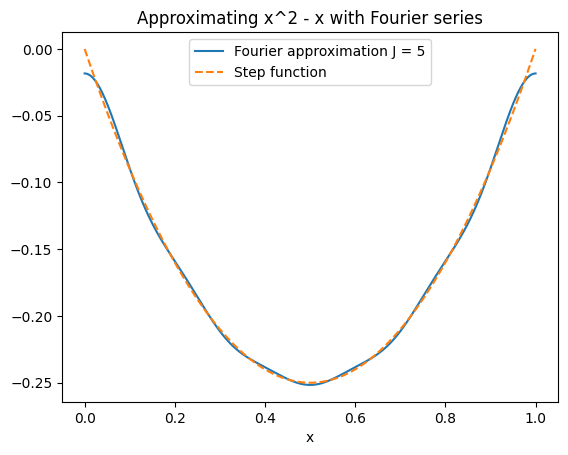

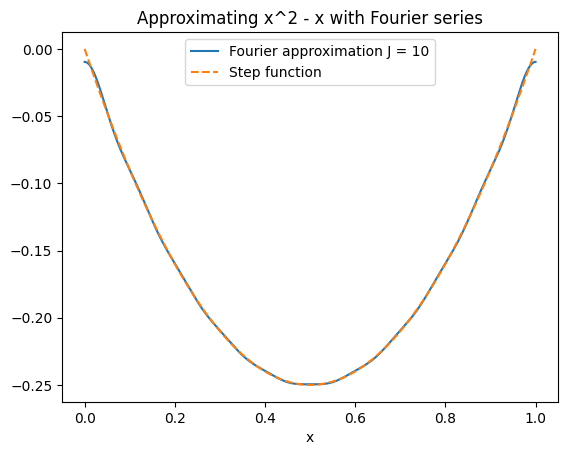

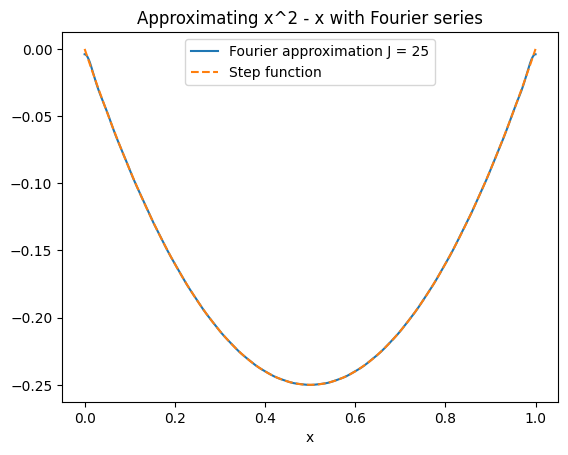

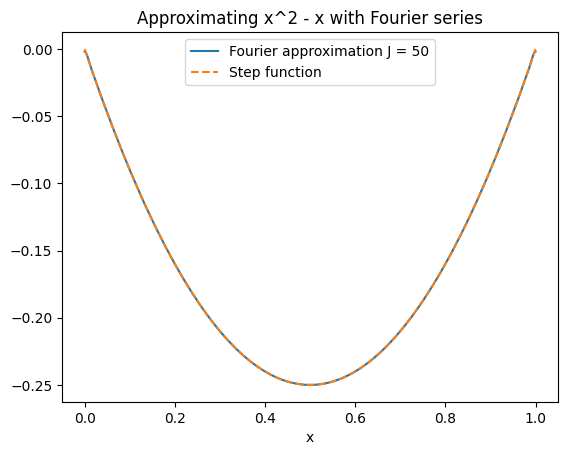

In [33]:
import numpy as np

def eval_uj(J, x):
	uJ_x = 0
	for k in range(-J, J + 1):
		u_k = 0
		if k == 0:
			u_k = - 1/6
		else:
			u_k = 1 / ( (np.pi **2) * (k**2) * 2)
		uJ_x += (u_k * np.exp(2 * np.pi * 1j * k * x))
	return uJ_x

def step_fn(J):
	N=1000
	grid=np.linspace(0,1,N)
	uJ = []
	for point in grid:
		uJ.append(eval_uj(J, point).real)
	return grid, uJ

import matplotlib.pyplot as plt

f = [x**2 - x for x in np.linspace(0,1,1000)]

J = [5,10,25,50]
for j in J:
	x, y = step_fn(j)
	plt.plot(x, y, label=f"Fourier approximation J = {j}")
	plt.plot(x, f, linestyle="dashed", label="Step function")
	plt.xlabel("x"); plt.title("Approximating x^2 - x with Fourier series"); plt.legend(loc="upper center")
	plt.show()
print()




### A4 Commentary
* Comparing to the step function, the Fourier approximation almost perfectly approximated $ u(x) $ by J = 25, with already substantial progress made by J = 5.
* As J increases, we can see a dampening in the oscillations again, with the tails almost perfectly matching at the endpoints with J = 50.
* It is clear that this function doesn't cause Gibbs' Phenomenom to occur, as it is a continuous polynomial

## A5

**a)**

Proceeding with integration by parts of $ u_j = \int_0^1 u(x) e^{-2 \pi j i x} \ dx $ with $ f(x) = u(x),  g(x) = e^{-2 j \pi i x}$:

$$
\begin{align*}
u_j & = \left[ \frac{u(x)e^{-2j \pi i x}}{-2 j \pi i } \right]_0^1 + \frac{1}{2 j \pi i} \int_0^1 u'(x) e^{-2j \pi i x} \\
& = \frac{1}{-2j \pi i}\left[u(1) - u(0)  \right] + \frac{1}{2 j \pi i} \int_0^1 u'(x) e^{-2j \pi i x} 
\end{align*}
$$

Now, taking the absolute value of both sides

$$
\begin{align*}

| u_j | & = \left| \frac{u(1) - u(0)}{2 \pi j} \right| + \left| \frac{1}{2j \pi} \int_0^1 u'(x) e^{-2j \pi i x} \ dx \right| \\
& \leq \frac{1}{2 \pi | j |} \left( \left| u(0) - u(1) \right | + \int_0^1 \left | u'(x) e^{-2 j \pi i x} \right | \right) \hspace{3mm} \mathbf{(4)}\\
& \leq \frac{1}{2 \pi | j |} \left( \left| u(0) - u(1) \right | + \int_0^1 \left | u'(x) \right | \right) \hspace{3mm} \mathbf{(5)} \\
& \leq \frac{C_1}{|j|}, \hspace{3mm} C_1 = \frac{1}{2 \pi }\left( \left| u(0) - u(1) \right | + \int_0^1 \left | u'(x) \right | \right) \hspace{3mm} \square
\end{align*}
$$

, with $ \leq $ introduced in $ \mathbf{(4)} $ due to this inequality: $ \left | \int_a^b f(x) \ dx \right | \leq \int_a^b | f(x) | \ dx $
<br> and with $ \mathbf{(5)} $ using the fact that $ e^{-2j \pi i x} \leq 1 \ \therefore \ u(x)e^{-2j \pi i x} \leq u(x) $

<br><br>

**b)**

To prove $ \int_0^1 (u(x) - \tilde{u}_J(x))^2 \ dx  \leq \frac{2C_1^2}{J-1}$, start by defining $e_J(x)$ as the error:

$$
\begin{align*}
e_J(x) & = u(x) - \tilde{u}_J(x)
& = \sum_{|k| > J}u_j e^{2 k \pi i x}
\end{align*}
$$

Parseval's Theorem states that $ \int_0^1 |u(x)|^2 \ dx \leq \sum_{k=-\infty}^{\infty} |u_k|^2 $

If we let the $ u(x) $ in Parseval's Theorem become our $ e_J(x) $, then the $ u_k $ coefficients for $ j \leq J $ become 0, and we achieve:

$$
\begin{align*}
\int_0^1 | e_J(x)|^2 \ dx & \leq \sum_{|k| > J} |u_k|^2 \\
& \leq \sum_{|k| > J} \left | \frac{C_1}{k} \right |^2 \\
& \leq 2C_1\sum_{k = J+1}^{\infty} \frac{1}{k^2}
\end{align*}
$$

It now suffices to prove $ \sum_{k = J+1}^{\infty} \frac{1}{k^2} \leq \frac{1}{J-1} $ to finish the proof

$$
\begin{align*}
k &> k-1 \hspace{4mm} (k>J>0) \\
k^2 &> k(k-1) \\
\frac{1}{k^2} &< \frac{1}{k(k-1)} \\
\sum_{k > J}^N \frac{1}{k^2} &< \sum_{k>J}^N \frac{1}{k(k-1)} \\
\end{align*}
$$

Using partial fractions, we can rewrite the RHS as:

$$
\begin{align*}
\sum_{k > J}^N \frac{1}{k(k-1)} &= \sum_{k>J}^N \frac{1}{k-1} - \frac{1}{k} \\
& = \frac{1}{J} - \frac{1}{J+1} \\
& + \frac{1}{J+1} - \frac{1}{J+2} \\
& + ... \\
& + \frac{1}{N-1} - \frac{1}{N} \\
& + \frac{1}{N} - \frac{1}{N+1}\\
\end{align*}
$$

After adding the telescopic sums, we get

$$
\sum_{k > J}^N \frac{1}{k(k-1)} = \frac{1}{J} - \frac{1}{N-1}
$$

Letting $ N \rightarrow \infty $,

$$
\begin{align*}
\sum_{k > J}^{\infty} \frac{1}{k(k-1)} &= \frac{1}{J} \\
& < \frac{1}{J-1}
\end{align*}
$$

So now, although a somewhat loose inequality,

$$
\sum_{k =J+1}^{\infty} \frac{1}{k^2} < \frac{1}{J-1}  \hspace{3mm} \square \\
$$

and finally

$$
\int_0^1 |e_j|^2 \ dx \leq 2C_1^2 \frac{1}{J-1} \hspace{3mm} \square
$$

<br>

**c)**

<br>

**d)**

In A2, we use the step function which is non-periodic and not continuously differentiable on [0,1] due to the lack of continuity at x=1/2. Thus none of the error upper bounds apply for this choice of $ u(x) $ and with the combination of Gibbs' phenomenon, the quality of approximation is extremely low.

However in A4, we have $ u(x) = x^2 - x$ which is both periodic and twice continuously differentiable on [0,1], since it is a polynomial of degree 2.

Using the inequality 

$$
\int_0^1 |u(x) - \tilde{u}_J(x)|^2 \ dx \leq \frac{C_2}{(J-1)^3}
$$

We can see that the error's rate of convergence is $ O(\frac{1}{J^3}) $, which with the graphs shown above, approximates extremely well even for smaller J. This, combined with the relative smoothness of the choice of $u(x)$ (first & second derivative are relatively small), the approximation is extremely high quality.





# Section B

## B1

Let each point on the mesh [0,1] be considered [$ \frac{j}{J}, \ j = 0...J $ ]
For this, consider the first and last few trapeziums made by the rule and their areas $A_k, \ k = 1\ ... \ J$

$$
\begin{align*}
A_1 & = h\frac{u(0) + u(1/J)}{2} \\
A_2 & = h\frac{u(1/J) + u(2/J)}{2} \\
... \\
A_{J-1} & = h\frac{u(J-2/J) + u(\frac{J-1}{J})}{2} \\
A_{J} & = h\frac{u(\frac{J-1}{J}) + u(1)}{2} \\
\end{align*}
$$

Remembering that $ u(1) = u(0), h = 1/J $ and noticing that each $ u(j/J) $ term is repeated twice, we get:

$$
\begin{align*}
T(u) & = A_1 + A_2 + ... + A_{J-1} + A_J \\
& = \frac{h}{2} \left( u(0) + 2u(1/J) + ... + 2u(\frac{J-2}{J}) + 2u\frac{J-1}{J} + u(1)  \right) \\
& = \frac{h}{2} \left( 2u(0) + 2u(1/J) + ... + 2u(\frac{J-2}{J}) + 2u\frac{J-1}{J} \right) \\
& = \frac{1}{J} \left( u(0) + u(1/J) + ... + u(\frac{J-2}{J}) + u\frac{J-1}{J} \right) \\
& = \frac{1}{J}\sum_{j=0}^{J-1}u(\frac{j}{J}) \hspace{3mm} \square
\end{align*}
$$



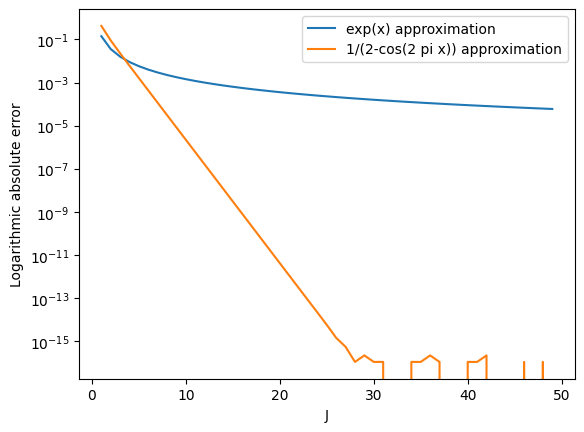

In [34]:
from scipy.integrate import quad

def per_trap(u,J):
	I = 0
	for j in range(0, J):
		I += u(j/J)
	return I/J

def non_per_trap(u,J):
	I = 0.5 * (u(0) + u(1))
	for j in range(1,J):
		I += u(j/J)
	return I/J
	
J = [i for i in range(1,50)]
errs_exp = []
errs_cos = []

for j in J:
	j = int(j) 

	I_exp = non_per_trap(lambda x: np.exp(x), j)
	I_cos = per_trap(lambda x: 1 / (2 - np.cos(2 * np.pi * x)), j)

	errs_exp.append(abs(I_exp - quad(np.exp, 0, 1)[0]))
	errs_cos.append(abs(I_cos - quad(lambda x: 1 / (2 - np.cos(2 * np.pi * x)), 0, 1 )[0]))

plt.semilogy(J, errs_exp, label="exp(x) approximation")
plt.semilogy(J, errs_cos, label="1/(2-cos(2 pi x)) approximation")
plt.xlabel("J"); plt.ylabel("Logarithmic absolute error"), plt.legend()

print()

## Main features observed
* The log(absolute error) of $ e^x $ converges to roughly $ 10^{-3} $ as J increases, with the shoulder of the curve occuring early on
* The log(absolute error) of the cos-related function decreases massivly compared to our exponential function, with errors as low as $ 10^{-15} $ as J approaches 40.
* As the error reaches $ 10^{-16} $, strange oscillations occur on the graph, likely due to precision/rounding errors within Python. As I'm on a 64-bit machine, any number smaller than $ 10^{-16} $ cannot be accuractely represented on my machine.

In [35]:
import sys

print("Machine epsilon:", sys.float_info.epsilon)

Machine epsilon: 2.220446049250313e-16


## B2

$$
\begin{align*}
 T(e^{2 k \pi i x}) &= \frac{1}{J} \sum_{j=0}^{J-1}e^{2 k \pi i j/J}
\end{align*}
$$

If $ k \cong 0 \mod J $, then $ k = mJ $ for some $ m $, and thus it becomes:

$$
\begin{align*}
 T(e^{2 k \pi i x}) &= \frac{1}{J} \sum_{j=0}^{J-1}e^{2 mJ \pi i j/J} \\
 & = \frac{1}{J} \sum_{j=0}^{J-1}e^{2 m \pi i j} \\
 & =  \frac{1}{J} \sum_{j=0}^{J-1}1 \\
& = 1
\end{align*}
$$

Otherwise, $ k \ncong 0 \mod J $, and $ T(u) $ becomes the sum of the J-th roots of unity, which we know to sum to 0.

From a proof in **A1**,
$$
\begin{align*}
\int_0^1 e^{2 \pi k i x} \ dx = 0
\end{align*}
$$

Now, to provide an expression for the error of $T(u)$,

$$
\begin{align*}
T(u) &= \frac{1}{J} \sum_{j=0}^{J-1} \sum_{k=-\infty}^{\infty} u_k e^{2 \pi k i x} \\
\end{align*}
$$

The inner sum converges according to the preamble for Section A, with the outer sum clearly finite. Thus, we swap the sums as follows:

$$
\begin{align*}
T(u) &= \sum_{k=-\infty}^{\infty} u_k \frac{1}{J} \sum_{j=0}^{J-1} e^{2 \pi k i x} \\
&= \sum_{k=mJ} (u_k \times 1) + \sum_{k \neq mJ} (u_k \times 0) \\
&= \sum_{k=mJ} u_k
\end{align*}
$$

It can also be easily shown that:
$$
\int_0^1 u(x) \ dx = \int_0^1u(x)e^0 = u_0 
$$:

The error can be finally simplified to:

$$
\begin{align*}
T(u) &= \left (\sum_{k=mJ} u_k \right ) - u_0 \\
&= \sum_{m \neq 0} u_{mJ} \hspace{3mm} \square
\end{align*}
$$


## B3


From the lecture notes, we know the theoretical upper bound on composite trapezium rules is

$$
\begin{align*}
\left | \int_a^b f(x) \ dx - Q_{1,J}^{[a,b]} \right | & = − \frac{1}{12} \sum_{j=1}^J h_j^3f^{(2)} \zeta_j \\
& \leq \frac{b-a}{12}||f^{(2)}||_{\infty, [a,b]}h^2
\end{align*}
$$

In the case of $ f(x) = exp(x) $,

$$
\begin{align*}
\left | \int_0^1 e^x \ dx - Q_{1,J}^{[0,1]} \right | & \leq \frac{1}{12} e^1 h^2 \\
& \leq \frac{C}{J^2}

\end{align*}
$$

This can explain the average convergence, with the error upper bound being $ O(\frac{1}{J^2}) $ <br>

Now when looking at our function $ u(x) = \frac{1}{2-cos(2 \pi x)} $, we can see this is periodic on [0,1]
<br> With this, we can begin to apply an argument from *Proof of Theorem 3.1 by Fourier Series and aliasing* **[1]**, which uses similar ideas to those in **B2**.

$$
\begin{align*}
\left | T(u) - I \right | & = \left |\sum_{m=\infty}^{\infty} u_{mJ} - I \right | 
& = \left | \sum_{m \neq 0} u_{mJ} \right |
\end{align*}
$$

Section 3 of **[1]** states that a periodic, analytic function will have exponentially decaying Fourier coefficients, with coefficients $ c_j \leq Me^{-ja}$ for some constant $M, a$

Thus, we can bound the error by

$$
\begin{align*}
\left | \sum_{m \neq 0} u_{mJ} \right | & \leq \sum_{m \neq 0} |u_{mJ} | \\
& \leq \sum_{m \neq 0} | Me^{-ja} | \\
\left | T(u) - I \right | & \leq \frac{M}{e^{2 \pi a J} - 1}
\end{align*}
$$

This theoretical upper bound on the error decays exponentially in J, explaining the huge difference in magnitude of the errors between $ 1/(2-cos(2 \pi x)) $ and $ e^x $

<br><br>
References 
- **[1]** https://epubs.siam.org/doi/pdf/10.1137/130932132



# Section C

## C1

Grey scaled shape: (750, 1250)


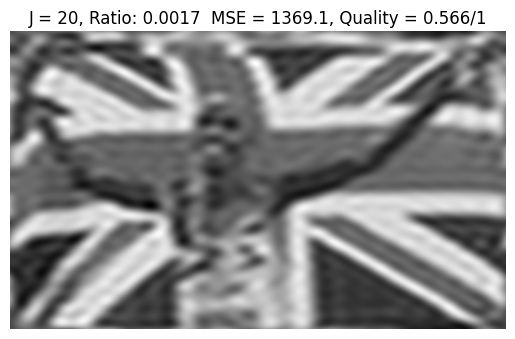

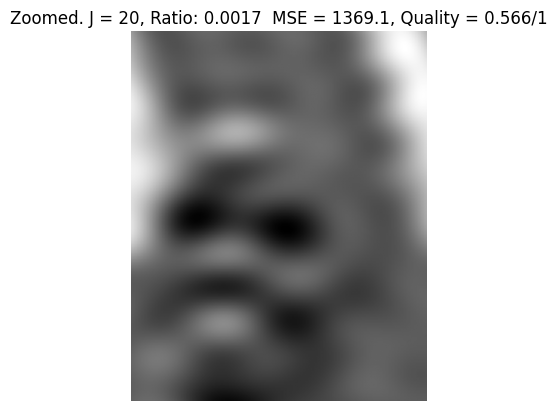

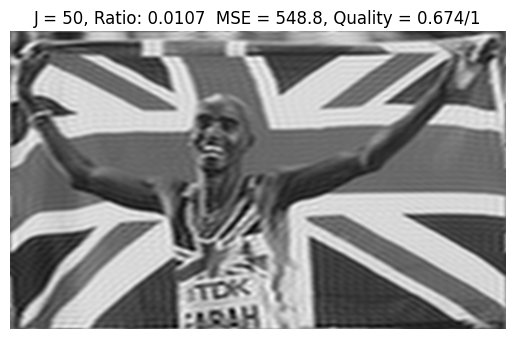

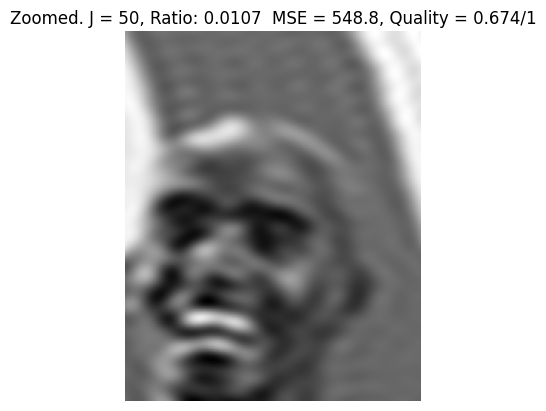

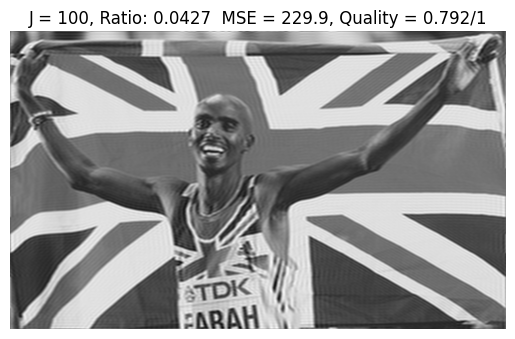

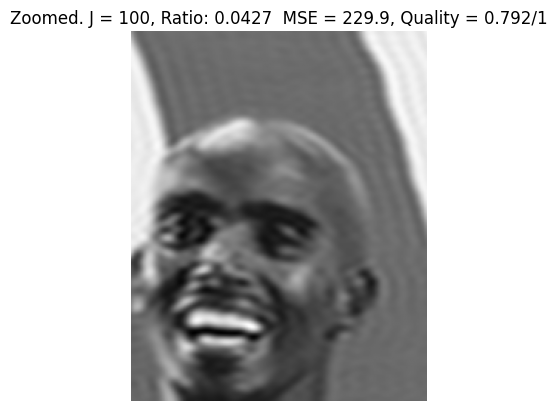

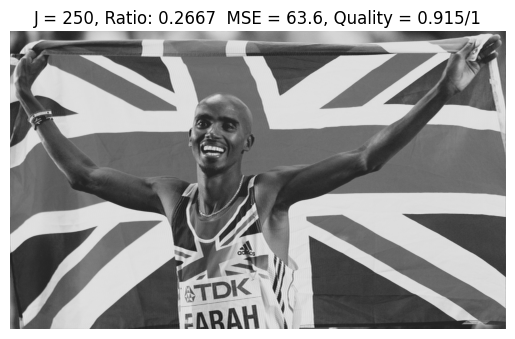

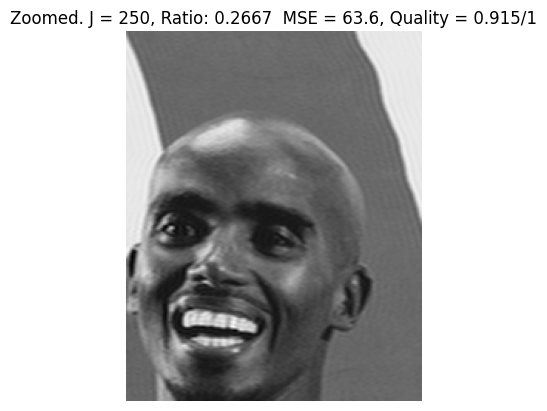

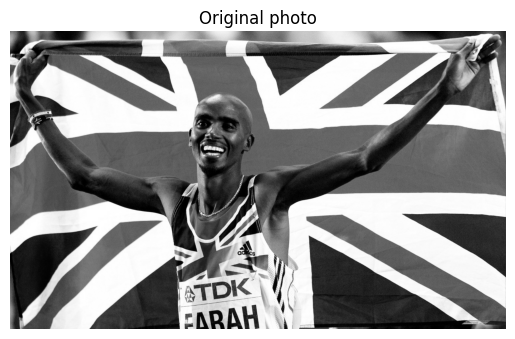

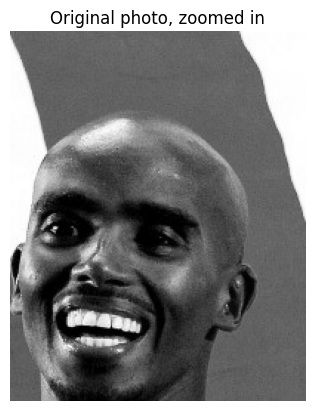

In [54]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import skimage as sk
import numpy as np

# For the image gray-scaling:
# https://www.geeksforgeeks.org/python/python-grayscaling-of-images-using-opencv/

# For research on compressed image quality metrics:
# https://www.mathworks.com/help/images/image-quality-metrics.html
# https://sumn2u.medium.com/quality-metrics-in-image-compression-f6de68df1b8

def mse(A, C): return np.mean((A-C)**2)

def ssim(A, C): 
	score, _ = sk.metrics.structural_similarity(A, C, full=True, data_range=(max(A.max(), C.max()) - min(A.min(), C.min())))
	return score

def compress(A, J):

	# Expect A to be a grayscale image i.e. [[int]]
	
	n, m = len(A), len(A[0])

	A_hat = np.fft.fft2(A)
	C_hat = np.zeros((n,m), dtype=complex)

	pred = lambda i, j: \
		(i < J and j < J) or \
		(i < J and j >= m - J) or \
		(i >= n - J and j < J) or \
		(i >= n - J and j >= m - J )
	
	for i in range(n):
		for j in range(m):
			C_hat[i][j] = A_hat[i][j] if pred(i,j) else 0
	
	C = np.real(np.fft.ifft2(C_hat))
	mse_compressed, ssim_compressed = mse(A, C), ssim(A,C)
	return C, round(mse_compressed,1) , round(ssim_compressed,3)

mo_img = mpimg.imread("image_mo.jpg")

weights = np.array([0.2989, 0.5870, 0.1140])
mo_img = mo_img @ weights 

print("Grey scaled shape:", mo_img.shape)

J = [20,50,100,250]

for j in J:
	compressed_img, err, qual = compress(mo_img, j)
	small_compressed_img = compressed_img[100:350, 450:650]

	plt.imshow(compressed_img, cmap="gray") # Display grayscale
	plt.title(f"J = {j}, Ratio: {round(4*j**2 / (mo_img.shape[0]*mo_img.shape[1]), 4)}  MSE = {err}, Quality = {qual}/1")
	plt.axis("off")
	plt.show()

	plt.imshow(small_compressed_img, cmap="gray") # Display grayscale
	plt.title(f"Zoomed. J = {j}, Ratio: {round(4*j**2 / (mo_img.shape[0]*mo_img.shape[1]), 4)}  MSE = {err}, Quality = {qual}/1")
	plt.axis("off")
	plt.show()

plt.imshow(mo_img, cmap="gray") # Display grayscale
plt.title("Original photo"); plt.axis("off"); plt.show()

small_mo = mo_img[100:350, 450:650]
plt.imshow(small_mo, cmap="gray") # Display grayscale
plt.title("Original photo, zoomed in"); plt.axis("off"); plt.show()




In the above plots:
* *J* is the side of the square corner coefficients taken
* *Ratio* is the number of Fourier coefficients kept vs original amount of coefficients $ \frac{4J^2}{n \times m} $
* *MSE* calculates the mean squared point-wise error between the original and compressed image
* I use SSIM (Structural Similarity) to obtain a score $ \in [0,1] $ detailing the quality of the compressed image. The closer to 1, the better matched the two images are

I found:
* As J increases, the compressed images become less blurry and reveal more edges, shadows, and fine detail. This is because the four $ J\times J $ corner blocks of $ \hat {A} $ contain the highest‑frequency Fourier coefficients. When J is small, only a tiny fraction of these high‑frequency components are kept, so the reconstruction shows only an outline of the image. As J grows, more high‑frequency information is retained, improving sharpness and detail in the reconstructed image.
* The main difference between the $ J=250 $ reconstruction and the original image is the lack of shadow/colour depth, not necessarily a blur effect like seen in smaller $ J $
* One of many artefacts shown is the complete lack of detail of Mo's eye in the $J=20$ example. In place of his eyes, there exists just a black hole. The embedding of the details of Mo's eyes must've not been within any of the $ 20 \times 20 $ corner squares, as there is absolutely information representing them shown. As J increases to 50, we can start to see his eye shape, eyebrows and eyelids start to develop



## C2

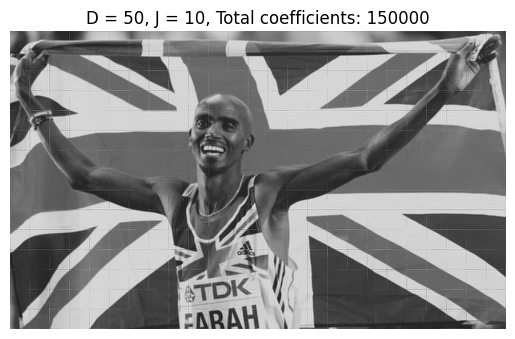

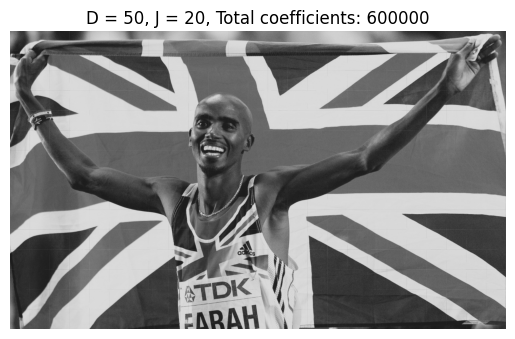

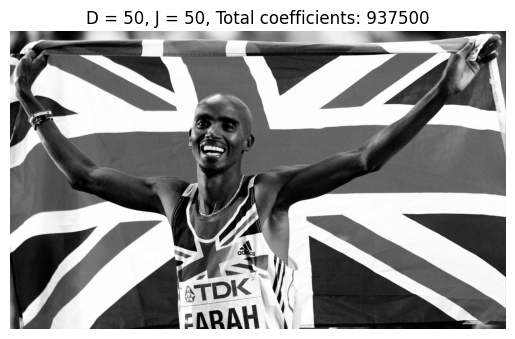

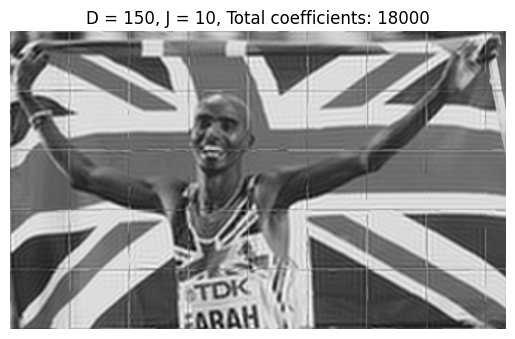

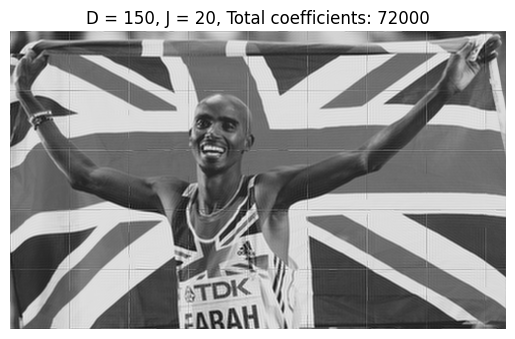

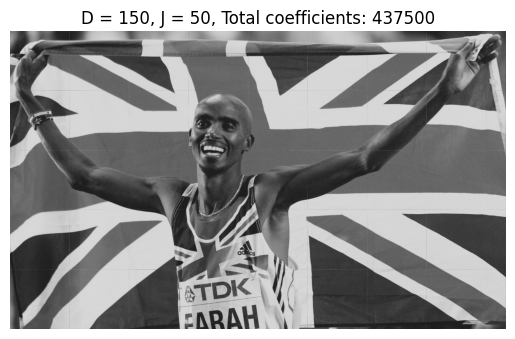

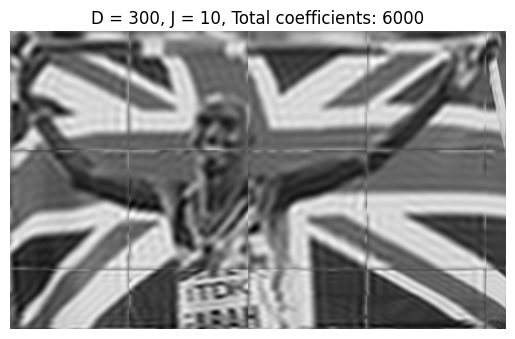

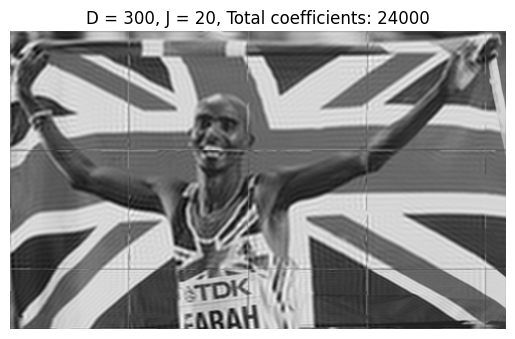

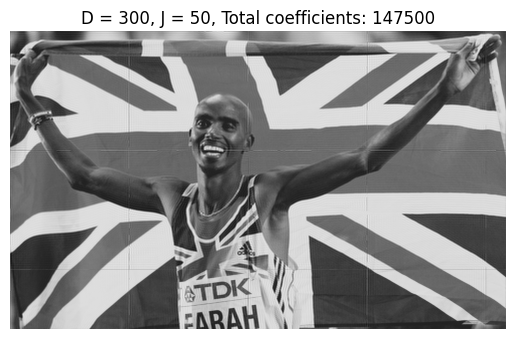

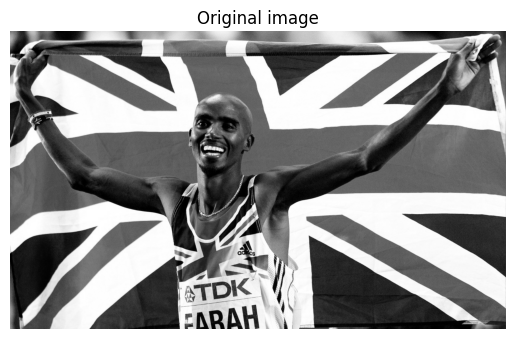

In [55]:
import itertools #std library

def compress_v2(im, J, D):
	C = np.zeros_like(im)
	n, m = im.shape
	total_coefficients = 0

	for i in range(0, n, D):
		for j in range(0, m, D):
			next_i = min(i+D, n)
			next_j = min(j+D, m)
			small_img = im[i:next_i, j:next_j]
			C_small, _, _ = compress(small_img, J)
			C[i:next_i, j:next_j] = C_small
			total_coefficients += min(4*J**2, C_small.shape[0] * C_small.shape[1])

	return C, total_coefficients

mo_img = mpimg.imread("image_mo.jpg")
weights = np.array([0.2989, 0.5870, 0.1140])
mo_img = mo_img @ weights 

grid = {"D": [50,150,300],
		"J": [10,20,50]}

keys = grid.keys()
configs = [dict(zip(keys, values)) for values in itertools.product(*grid.values())]

configs = sorted(configs, key=lambda d: (d["D"], d["J"]))

for cfg in configs:
	D = cfg["D"]
	J = cfg["J"]
	compressed_img, total_coeff = compress_v2(mo_img, J, D)
	plt.imshow(compressed_img, cmap="gray")
	plt.title(f"D = {D}, J = {J}, Total coefficients: {total_coeff}"); plt.axis("off"); plt.show()

plt.imshow(mo_img, cmap="gray")
plt.title("Original image"); plt.axis("off"); plt.show()

